<table style="width:100%; border-collapse:collapse; border-spacing:0; border:none; border-bottom:2px solid #e0e0e0; margin-bottom:16px; padding:0; margin-top:0;">
  <tr style="border:none; padding:0; margin:0;">
    <td style="width:144px; padding:16px 24px 16px 0; vertical-align:middle; border:none; outline:none; box-shadow:none;">
      <img src="https://github.com/TUIlmenauAMS/fs-ws2627-pinn-guitar/blob/main/assets/ams_group_tui.png?raw=1" width="120" style="border-radius:12px; display:block; margin:0;"/>
    </td>
    <td style="padding:16px 0 16px 0; vertical-align:middle; border:none; outline:none; box-shadow:none;">
      <h1 style="margin:0 0 4px 0; padding:0;">Forschungsseminar – Medieningenieurwissenschaften</h1>
      <h2 style="margin:0 0 8px 0; padding:0;">NB01: PDE Basics</h2>
      <p style="margin:0; padding:0;">
        <b>Institut für Medientechnik – Technische Universität Ilmenau</b><br>
        <a href="https://www.tu-ilmenau.de/universitaet/fakultaeten/fakultaet-elektrotechnik-und-informationstechnik/profil/institute-und-fachgebiete/fachgebiet-angewandte-mediensysteme" target="_blank">Institut für Medientechnik – AMS Group</a>
      </p>
      <p style="margin:4px 0 0 0; padding:0;">
        <b>Fachgebietsleiter:</b> Prof. Dr.-Ing. Gerald Schuller<br>
        <b>Wissenschaftlicher Mitarbeiter:</b> Renato Fera P. <a href="https://www.linkedin.com/in/renato-profeta/" target="_blank">LinkedIn</a>
      </p>
    </td>
  </tr>
</table>

In [1]:
# ── Environment detection ──────────────────────────────────────────────────────
# Runs automatically. Installs packages on Colab; confirms venv on local/Codespaces.
import sys, subprocess

def _in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if _in_colab():
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy", "matplotlib", "sympy"])
    print("✓ Colab — packages installed via pip.")
else:
    # Local VS Code or GitHub Codespaces:
    # packages are managed by uv (pyproject.toml). Run 'uv sync' once in the
    # repo root, then select the .venv interpreter as the kernel in VS Code.
    print("✓ Local / Codespaces — using uv-managed venv.")
# ──────────────────────────────────────────────────────────────────────────────

✓ Colab — packages installed via pip.


# NB01: PDE Basics

> **After this notebook you will be able to:**
> - Explain what a PDE is and how it differs from an ODE
> - Identify boundary conditions (Dirichlet, Neumann) and initial conditions
> - Write down the 1D heat equation and explain what each term means physically
> - Visualise PDE solutions as heatmaps and line plots in Python
> - Use SymPy to display and verify mathematical equations symbolically

In [2]:
# ── SymPy setup — symbolic variables used throughout this notebook ─────────────
import sympy as sp
from sympy import (symbols, Function, Eq, sin, cos, exp, pi,
                   diff, simplify, factor)
from IPython.display import display

# Independent variables
x, t = sp.symbols('x t', real=True)

# Physical parameters (all positive)
L, alpha, c, k = sp.symbols('L alpha c k', positive=True)

# u is the unknown function of x and t (used for PDEs)
u = sp.Function('u')

# y is a function of t only (used for the ODE example)
y = sp.Function('y')

# Enable LaTeX rendering in notebook output
sp.init_printing(use_latex='mathjax')

print("✓ SymPy symbolic variables defined. All subsequent cells can use them.")
# ──────────────────────────────────────────────────────────────────────────────

✓ SymPy symbolic variables defined. All subsequent cells can use them.


---

## 1. What is a PDE?

A **PDE (Partial Differential Equation)** is an equation that relates a function of *several* variables to its partial derivatives. The function we are trying to find is unknown — the PDE is the rule it must obey everywhere in space and time.

### 1.1 Contrast with an ODE

An **ODE (Ordinary Differential Equation)** involves a function of only *one* independent variable. A helpful analogy:

- An **ODE** tracks how one quantity (e.g. a population) changes over time — one axis.
- A **PDE** tracks how a quantity changes across both space *and* time simultaneously — a whole surface of values.

### 1.2 Examples

| Equation | Type | Physical meaning |
|----------|------|------------------|
| $\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}$ | PDE — parabolic | Heat diffusion along a rod |
| $\frac{\partial^2 u}{\partial t^2} = c^2 \frac{\partial^2 u}{\partial x^2}$ | PDE — hyperbolic | Wave propagation on a string |
| $\frac{dy}{dt} = -k\,y$ | ODE | Radioactive decay |

### 1.3 Bridge to the project

The stiff guitar string in the project is governed by a **hyperbolic PDE** (wave-like), with an extra fourth-order term that makes the string stiff. The 1D heat equation is simpler (parabolic, second-order) — we use it as the teaching example in this notebook so you can focus on the *structure* of PDEs.

In [3]:
# ── The three equations from the table, written as SymPy objects ───────────────

# 1. Heat equation: ∂u/∂t = α ∂²u/∂x²
heat_eq = Eq(u(x, t).diff(t), alpha * u(x, t).diff(x, 2))
print("Heat equation (parabolic PDE):")
display(heat_eq)

# 2. Wave equation: ∂²u/∂t² = c² ∂²u/∂x²
wave_eq = Eq(u(x, t).diff(t, 2), c**2 * u(x, t).diff(x, 2))
print("Wave equation (hyperbolic PDE):")
display(wave_eq)

# 3. ODE: dy/dt = -k·y
ode_eq = Eq(y(t).diff(t), -k * y(t))
print("Radioactive decay ODE:")
display(ode_eq)
# ──────────────────────────────────────────────────────────────────────────────

Heat equation (parabolic PDE):


                 2          
∂               ∂           
──(u(x, t)) = α⋅───(u(x, t))
∂t                2         
                ∂x          

Wave equation (hyperbolic PDE):


 2                 2          
∂               2 ∂           
───(u(x, t)) = c ⋅───(u(x, t))
  2                 2         
∂t                ∂x          

Radioactive decay ODE:


d                 
──(y(t)) = -k⋅y(t)
dt                

---

## 2. The 1D heat equation

**Physical setup:** Imagine a thin metal rod of length $L$, insulated along its sides so heat can only flow left and right. We want to know the temperature $u(x, t)$ at every position $x \in [0, L]$ and every time $t \geq 0$.

**The PDE:**

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}$$

### Symbol table

| Symbol | Meaning | Typical unit |
|--------|---------|-------------|
| $u(x,t)$ | Temperature at position $x$, time $t$ | °C |
| $x$ | Position along the rod | m |
| $t$ | Time | s |
| $\alpha$ | Thermal diffusivity (material constant) | m²/s |
| $L$ | Length of the rod | m |

### Term-by-term intuition

- **Left side** $\partial u / \partial t$: how fast the temperature at a point is changing in time — positive means heating up, negative means cooling down.
- **Right side** $\alpha \, \partial^2 u / \partial x^2$: the *curvature* of the temperature profile in space. If a point is hotter than its neighbours (a peak), $\partial^2 u / \partial x^2 < 0$, so the temperature there decreases — the heat spreads outward. If a point is cooler (a valley), it heats up.

> **Key insight:** The PDE says: *the more curved the profile, the faster it flattens.*

**Connection to the guitar string:** In the project, $u(x,t)$ will be the transverse displacement of the string (not temperature), and the PDE will have additional terms — but the same intuition about spatial derivatives driving time evolution applies.

In [4]:
# ── Heat equation as a SymPy object ───────────────────────────────────────────
print("The 1D heat equation:")
heat_eq = Eq(u(x, t).diff(t), alpha * u(x, t).diff(x, 2))
display(heat_eq)

# ── Exact solution for u(x, 0) = sin(πx/L) with Dirichlet BCs ────────────────
u_exact = sin(pi * x / L) * exp(-alpha * (pi / L)**2 * t)
print("\nExact analytical solution:")
display(Eq(u(x, t), u_exact))

# ── Symbolic verification: substitute into PDE and check residual ─────────────
lhs = u_exact.diff(t)                        # left side: ∂u/∂t
rhs = alpha * u_exact.diff(x, 2)             # right side: α ∂²u/∂x²
residual = simplify(lhs - rhs)               # should be zero if u satisfies PDE

print("\nPDE verification — left side minus right side (should be 0):")
display(residual)

if residual == 0:
    print("✓ The exact solution satisfies the heat equation.")
# ──────────────────────────────────────────────────────────────────────────────

The 1D heat equation:


                 2          
∂               ∂           
──(u(x, t)) = α⋅───(u(x, t))
∂t                2         
                ∂x          


Exact analytical solution:


             2              
           -π ⋅α⋅t          
           ────────         
               2            
              L        ⎛π⋅x⎞
u(x, t) = ℯ        ⋅sin⎜───⎟
                       ⎝ L ⎠


PDE verification — left side minus right side (should be 0):


0

✓ The exact solution satisfies the heat equation.


---

## 3. Boundary and initial conditions

**Why are conditions needed?** A PDE alone has infinitely many solutions. Conditions select the unique one that matches the physical setup. Analogy: $dy/dx = 2x$ has the solution family $y = x^2 + C$; specifying $y(0) = 3$ pins down $C = 3$ uniquely.

### Initial condition (IC)

Specifies the full state of the system at $t = 0$:

$$u(x,\,0) = f(x) \quad \text{for all } x \in [0, L]$$

This is the temperature profile along the rod at the moment we start observing it.

### Boundary conditions (BC)

Specify what happens at the spatial edges $x = 0$ and $x = L$ for all $t > 0$.

- **Dirichlet BC** — fix the *value* of $u$ at the boundary:
  $u(0,t) = 0$ and $u(L,t) = 0$. Physically: both ends are held in ice water (0 °C).

- **Neumann BC** — fix the *spatial derivative* of $u$ at the boundary:
  $\frac{\partial u}{\partial x}\big|_{x=0} = 0$. Physically: the left end is insulated (no heat flows out).

> **Fixed setup for this notebook:**
> - **Dirichlet BCs:** $u(0,t) = 0$ and $u(L,t) = 0$ — both ends held at zero.
> - **Sinusoidal IC:** $u(x,0) = \sin(\pi x / L)$ — a smooth arch that is already zero at both ends, so it is automatically consistent with the BCs.

Why is this IC convenient? Because $\sin(\pi \cdot 0 / L) = 0$ and $\sin(\pi \cdot L / L) = \sin(\pi) = 0$, the IC already satisfies the BCs at $t = 0$.

**Connection to the guitar string:** The stiff string project uses a similar pair of Dirichlet conditions ($u = 0$ at both ends) plus two additional conditions on the second spatial derivative ($\partial^2 u / \partial x^2 = 0$ at both ends, the simply-supported / pinned-end condition). Four conditions are needed because the string PDE is fourth-order in space.

In [5]:
# ── Initial condition: u(x, 0) = sin(πx/L) ───────────────────────────────────
u0 = sin(pi * x / L)
print("Initial condition:")
display(Eq(u(x, 0), u0))

# ── Dirichlet boundary conditions ─────────────────────────────────────────────
print("\nDirichlet boundary conditions:")
display(Eq(u(0, t), 0))
display(Eq(u(L, t), 0))

# ── Neumann boundary condition (for reference) ────────────────────────────────
print("\nNeumann BC (insulated left end — not used here, shown for reference):")
display(Eq(u(x, t).diff(x).subs(x, 0), 0))

# ── Verify: IC satisfies the Dirichlet BCs at t = 0 ──────────────────────────
val_left  = simplify(u0.subs(x, 0))    # u(0, 0)
val_right = simplify(u0.subs(x, L))    # u(L, 0)

print("\nConsistency check — does the IC satisfy the BCs?")
display(Eq(u(0, 0), val_left))         # should display u(0,0) = 0
display(Eq(u(L, 0), val_right))        # should display u(L,0) = 0

if val_left == 0 and val_right == 0:
    print("✓ The initial condition satisfies both Dirichlet BCs.")
# ──────────────────────────────────────────────────────────────────────────────

Initial condition:


             ⎛π⋅x⎞
u(x, 0) = sin⎜───⎟
             ⎝ L ⎠


Dirichlet boundary conditions:


u(0, t) = 0

u(L, t) = 0


Neumann BC (insulated left end — not used here, shown for reference):


⎛∂          ⎞│       
⎜──(u(x, t))⎟│    = 0
⎝∂x         ⎠│x=0    


Consistency check — does the IC satisfy the BCs?


u(0, 0) = 0

u(L, 0) = 0

✓ The initial condition satisfies both Dirichlet BCs.


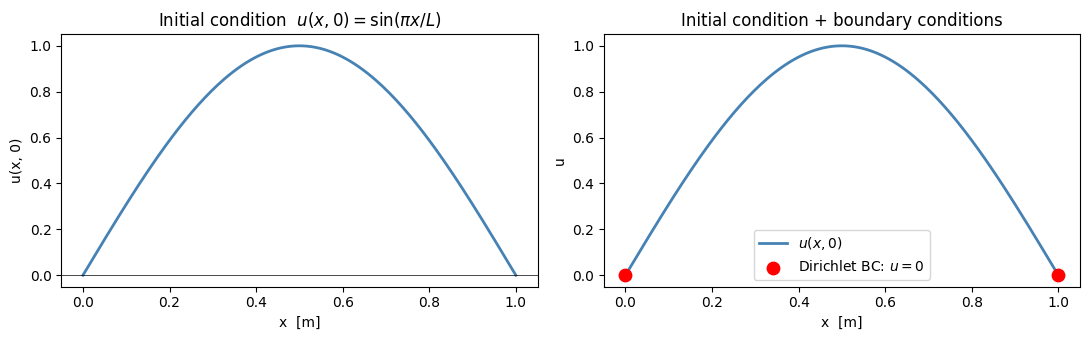

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ── Grid setup ────────────────────────────────────────────────────────────────
L_num = 1.0      # rod length [m]  (numerical value; L is the SymPy symbol above)
N     = 200      # number of spatial points
x_num = np.linspace(0, L_num, N)

# ── Initial condition: u(x, 0) = sin(πx/L) ───────────────────────────────────
u0_num = np.sin(np.pi * x_num / L_num)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

# Left panel — the initial condition alone
axes[0].plot(x_num, u0_num, lw=2, color='steelblue')
axes[0].set(title=r'Initial condition  $u(x,0) = \sin(\pi x / L)$',
            xlabel='x  [m]', ylabel='u(x, 0)')
axes[0].axhline(0, color='k', lw=0.5)

# Right panel — IC with Dirichlet boundary conditions highlighted
axes[1].plot(x_num, u0_num, lw=2, color='steelblue', label=r'$u(x,0)$')
axes[1].scatter([0, L_num], [0, 0], color='red', zorder=5, s=80,
                label='Dirichlet BC: $u = 0$')
axes[1].set(title='Initial condition + boundary conditions',
            xlabel='x  [m]', ylabel='u')
axes[1].legend()

plt.tight_layout()
plt.show()

---

## 4. How to read a PDE solution: space–time plots

**The solution is a surface:** $u(x,t)$ assigns a value to every $(x, t)$ pair. It cannot be drawn as a single 2D curve; we need specialised visualisations.

### Two standard visualisations

1. **Snapshot line plots:** Choose a set of times $t_1 < t_2 < \ldots$ and plot $u(x, t_i)$ as a curve for each. Each curve is one horizontal “slice” through the solution surface. Easy to read exact values; good for comparing the profile at different moments.

2. **Space–time heatmap:** Place $x$ on the horizontal axis and $t$ on the vertical axis. Colour each pixel by the value of $u(x,t)$. Shows the entire solution at a glance — diffusion fronts, decay, oscillations are all immediately visible as patterns.

### How to read a heatmap axis by axis

- A horizontal *row* at height $t = t_0$ is the spatial profile at that instant.
- A vertical *column* at position $x = x_0$ is how the temperature at that point evolves over time.
- Bright (or warm-coloured) areas are high values; dark areas are low values.

In [7]:
# ── The exact solution we are about to plot ───────────────────────────────────
print("Exact solution (single-mode heat equation):")
display(Eq(u(x, t), u_exact))          # u_exact was defined in Cell 10

# ── The decay rate λ = α(π/L)² ───────────────────────────────────────────────
lam = alpha * (pi / L)**2              # eigenvalue / decay rate
print("\nDecay rate  λ = α(π/L)²:")
display(Eq(sp.Symbol('lambda'), lam))

print("\nThe amplitude decays as exp(−λt). Larger λ → faster decay.")
print("At fixed L, increasing α (more diffusive material) makes the rod cool faster.")
# ──────────────────────────────────────────────────────────────────────────────

Exact solution (single-mode heat equation):


             2              
           -π ⋅α⋅t          
           ────────         
               2            
              L        ⎛π⋅x⎞
u(x, t) = ℯ        ⋅sin⎜───⎟
                       ⎝ L ⎠


Decay rate  λ = α(π/L)²:


     2  
    π ⋅α
λ = ────
      2 
     L  


The amplitude decays as exp(−λt). Larger λ → faster decay.
At fixed L, increasing α (more diffusive material) makes the rod cool faster.


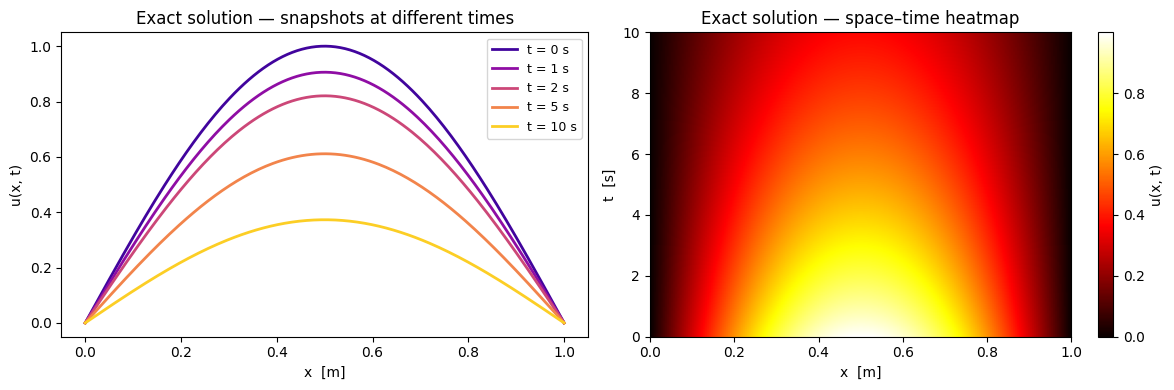

In [8]:
# ── Parameters ────────────────────────────────────────────────────────────────
alpha_num = 0.01    # thermal diffusivity [m²/s]
T_end     = 10.0    # end time for visualisation [s]
Nt        = 500     # time grid points

t_num = np.linspace(0, T_end, Nt)

# ── Exact solution on a 2D grid: U[i_time, i_space] ──────────────────────────
X_grid, T_grid = np.meshgrid(x_num, t_num)
U = np.sin(np.pi * X_grid / L_num) * np.exp(-alpha_num * (np.pi / L_num)**2 * T_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left panel — snapshot line plots at selected times
snapshot_times = [0, 1, 2, 5, 10]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(snapshot_times)))
for t_snap, col in zip(snapshot_times, colors):
    idx = np.argmin(np.abs(t_num - t_snap))   # find nearest time index
    axes[0].plot(x_num, U[idx], color=col, lw=2, label=f't = {t_snap} s')
axes[0].set(title='Exact solution — snapshots at different times',
            xlabel='x  [m]', ylabel='u(x, t)')
axes[0].legend(fontsize=9)

# Right panel — space–time heatmap (x horizontal, t vertical)
im = axes[1].imshow(U, aspect='auto', origin='lower',
                    extent=[0, L_num, 0, T_end], cmap='hot')
plt.colorbar(im, ax=axes[1], label='u(x, t)')
axes[1].set(title='Exact solution — space–time heatmap',
            xlabel='x  [m]', ylabel='t  [s]')

plt.tight_layout()
plt.show()

**What you should see:**
- **Snapshots (left):** The initial arch gradually shrinks and flattens. By $t = 10$ s the rod is nearly at uniform temperature (zero). The decay is smooth and exponential.
- **Heatmap (right):** The top of the image (large $t$) is dark — the rod has cooled. The bottom (small $t$) is bright. The smooth arch at $t = 0$ is visible at the very bottom row. No oscillations — the heat equation only diffuses, it does not wave.

> The stiff guitar string solution will look very different: the heatmap will show travelling and reflecting waves, with high-frequency components decaying faster than low ones due to the stiffness and damping terms in the PDE.

---

## 5. Summary

**Three things you now know:**

1. A PDE is an equation involving a function of several variables and its partial derivatives. It governs how a quantity evolves everywhere in space and time.
2. A unique solution requires an **initial condition** (the state at $t = 0$) and **boundary conditions** (the behaviour at the spatial edges for all $t > 0$).
3. PDE solutions are visualised as **snapshot line plots** (one curve per time instant) or as **space–time heatmaps** (the full solution as a colour image).

**SymPy takeaway:** Every equation in this notebook was written both as LaTeX and as a live SymPy object. SymPy lets you display, manipulate, and verify mathematical expressions directly in Python — this is a tool you will use throughout the project.

**Connection to the stiff guitar string project:**
The stiff string PDE has the same two-variable structure $u(x,t)$, the same type of initial condition (a plucked profile), and the same type of Dirichlet boundary conditions ($u = 0$ at both ends). The differences are that it is a *wave* equation (second time derivative, not first), and it adds a fourth-order bending stiffness term and damping terms. The key concepts from this notebook — what a PDE is, what conditions pin down a unique solution, and how to read a space–time plot — apply directly to the project.

---

<div style="text-align:center; padding:18px 0 8px 0; margin-top:24px; border-top:2px solid #e0e0e0;">
  <p style="margin:0 0 6px 0;">
    <b>Forschungsseminar – Medieningenieurwissenschaften</b> &middot; NB01: PDE Basics<br>
    Institut für Medientechnik &ndash; Technische Universität Ilmenau
  </p>
  <p style="margin:0; font-size:0.95em;">
    Notebook created by <b>Renato Fera P.</b> &middot;
    <a href="https://www.linkedin.com/in/renato-profeta/" target="_blank">LinkedIn</a>
  </p>
</div>